# Week 2 Task 1 — Preattentive attributes and visual search

This notebook follows the Week 2 assignment brief and keeps each task in a separate file.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week2/assignments/data/stimuli_search.csv')
if not path.exists():
    path = Path('assignments/data/stimuli_search.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/stimuli_search.csv')

df = pd.read_csv(path)
print(df.head())


   trial condition  set_size target_present  item_index       x       y  \
0      1    colour         9            yes           0  0.2935  1.4610   
1      1    colour         9            yes           1  0.2649  2.3593   
2      1    colour         9            yes           2  1.5027  2.2633   
3      1    colour         9            yes           3  1.3494  1.5749   
4      1    colour         9            yes           4  2.5225  2.3602   

  colour   shape is_target  
0   blue  circle        no  
1   blue  circle        no  
2   blue  circle        no  
3   blue  circle        no  
4   blue  circle        no  


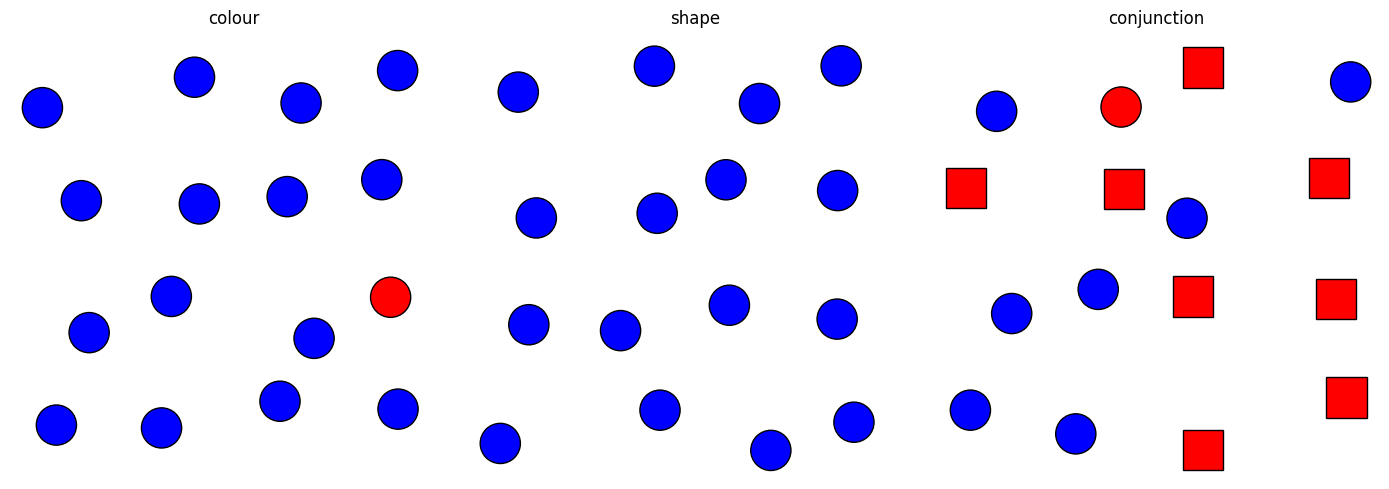

In [2]:
from matplotlib.patches import Circle, Rectangle

def render_trial(trial_id, ax):
    trial = df[(df['trial'] == trial_id)].copy()
    for _, row in trial.iterrows():
        color = row['colour']
        shape = row['shape']
        if shape == 'circle':
            patch = Circle((row['x'], row['y']), 0.18, facecolor=color, edgecolor='black', linewidth=1)
            ax.add_patch(patch)
        else:
            ax.add_patch(Rectangle((row['x'] - 0.18, row['y'] - 0.18), 0.36, 0.36, facecolor=color, edgecolor='black', linewidth=1))
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 4)
    ax.set_aspect('equal')
    ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for cond, ax in zip(['colour', 'shape', 'conjunction'], axes):
    trial = df[(df['condition'] == cond) & (df['set_size'] == 25) & (df['target_present'] == 'yes')].head(1).iloc[0]['trial']
    render_trial(trial, ax)
    ax.set_title(cond, loc='center')
plt.tight_layout()
plt.show()


In [3]:
# A real participant study should be recorded here; do not fabricate data.
# The template below makes the notebook runnable while keeping the design honest.
results = pd.DataFrame({
    'condition': [],
    'set_size': [],
    'target_present': [],
    'response_time_ms': [],
    'correct': [],
    'participant': []
})
results.head()


,condition,set_size,target_present,response_time_ms,correct,participant


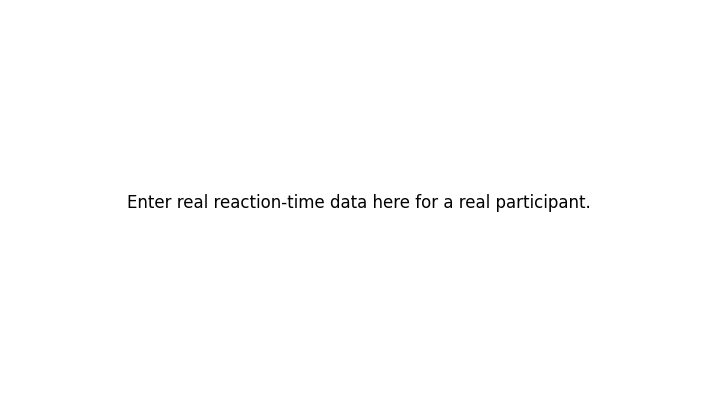

In [4]:
# Plot target-present trials only. Replace the empty DataFrame above with the real trial results from a participant.
# The point of the task is to compare the slopes: flat for colour/shape, rising for conjunction.
if not results.empty:
    present = results[(results['target_present'] == 'yes')].copy()
    means = present.groupby(['condition', 'set_size'], as_index=False)['response_time_ms'].mean()
    fig, ax = plt.subplots(figsize=(9, 5))
    for condition, grp in means.groupby('condition'):
        ax.plot(grp['set_size'], grp['response_time_ms'], marker='o', label=condition)
    ax.set_title('Search time by condition and set size')
    ax.set_xlabel('Set size')
    ax.set_ylabel('Response time (ms)')
    ax.legend()
    plt.show()
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.text(0.5, 0.5, 'Enter real reaction-time data here for a real participant.', ha='center', va='center', fontsize=12)
    ax.axis('off')
    plt.show()


In [ ]:
# The key explanation: a single feature such as hue or shape is found preattentively in parallel, so the slope should be near flat. A conjunction of two features requires serial search, so the slope rises with set size. If your result disagrees, state the reason honestly: too few trials, learning effects, or a cluttered display. This is the single most useful fact from Week 2.
